# UTS Graf Sains Data (GSD)
**Nama:** Muhammad Dafa Alvian Ramadhani  
**NIM:** 23031554017  
**Kelas:** Sains Data 23 B  

---
## 1. Tugas Pendahuluan
### 1.1 Persiapan dan Perkenalan Lingkungan & 1.2 Mempelajari Penggunaan Driver Neo4J

In [8]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "adminbesar")

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print("Teman Arthur:")
    print_friends(driver, "Arthur")

Teman Arthur:
Guinevere
Lancelot
Merlin


### Pertanyaan Pendahuluan (Checkpoint)
1. **Apa nama database yang digunakan pada tutorial ini?**
   - Database yang digunakan adalah `neo4j`.
2. **Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!**
   - Berpindah database: `USE nama_database;`
   - Perintah DDL/DML: `CREATE DATABASE nama_db;`, `SHOW DATABASES;`, `DROP DATABASE nama_db;`.
3. **Apa jenis graf pertemanan yang telah dibuat di sini?**
   - Graf berarah (*Directed Graph*), karena hubungan dibentuk dari simpul asal ke simpul tujuan melalui pola `(a)-[:KNOWS]->(friend)`.

In [9]:
# CYPHER Total Reset (Batched Execution)
# Jalankan perintah berikut untuk melakukan truncate pada konten database: MATCH (n) DETACH DELETE n;
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        print("Memulai pembersihan database secara bertahap...")
        while True:
            result = session.run("""
            MATCH (n)
            WITH n LIMIT 10000
            DETACH DELETE n
            RETURN count(n) AS total
            """)
            deleted_count = result.single()["total"]
            if deleted_count == 0:
                break

print("Database Neo4j berhasil dibersihkan total (Clean State).")

Memulai pembersihan database secara bertahap...
Database Neo4j berhasil dibersihkan total (Clean State).


### Penjelasan CYPHER Total Reset
Perintah `MATCH (n) WITH n LIMIT 10000 DETACH DELETE n` dieksekusi secara berulang (*batching*) agar pembersihan jutaan node/relasi percobaan awal tidak memicu eror memori (*MemoryPoolOutOfMemoryError*).

In [10]:
import os
import pandas as pd

df = pd.read_csv('data/events.csv')

df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

# Filter Periode Khusus MUHAMMAD DAFA ALVIAN RAMADHANI
# Fold Training (P1): 04/05/2015 s.d. 04/07/2015
# Fold Testing (P2) : 13/07/2015 s.d. 28/07/2015
train_start, train_end = '2015-05-04', '2015-07-04'
test_start, test_end = '2015-07-13', '2015-07-28'

df_train = df[(df['datetime'] >= train_start) & (df['datetime'] <= train_end)].copy()
df_test = df[(df['datetime'] >= test_start) & (df['datetime'] <= test_end)].copy()

# Simpan hasil filter ke folder processed_data
os.makedirs('processed_data', exist_ok=True)
df_train.to_csv('processed_data/events_train.csv', index=False)
df_test.to_csv('processed_data/events_test.csv', index=False)

print(f"P1 Training Data : {len(df_train):,} baris | Visitor Unik: {df_train['visitorid'].nunique():,} | Item Unik: {df_train['itemid'].nunique():,}")
print(f"P2 Testing Data  : {len(df_test):,} baris | Visitor Unik: {df_test['visitorid'].nunique():,} | Item Unik: {df_test['itemid'].nunique():,}")

P1 Training Data : 1,250,321 baris | Visitor Unik: 630,720 | Item Unik: 166,214
P2 Testing Data  : 356,242 baris | Visitor Unik: 197,158 | Item Unik: 87,738


### Penjelasan Eksekusi Filter Sebelum Instruksi 1.3
Eksekusi pemotongan timestamp dijalankan terlebih dahulu karena Instruksi 1.3 membutuhkan file `processed_data/events_train.csv` di sistem lokal.

In [11]:
from tqdm import tqdm

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})
    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'addtocart'
        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row WHERE row.event = 'transaction'
        MERGE (v)-[:BOUGHT {timestamp: row.timestamp, transactionid: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

driver = GraphDatabase.driver(URI, auth=AUTH)
batch_size = 5000

with driver.session() as session:
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorid IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemid IS UNIQUE")
    
    chunks = pd.read_csv('processed_data/events_train.csv', chunksize=batch_size)
    total_rows = len(df_train)
    total_chunks = (total_rows // batch_size) + 1
    
    print("Memulai proses impor batch data P1 ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch"):
        chunk['transactionid'] = chunk['transactionid'].fillna('').astype(str)
        records = chunk.to_dict(orient='records')
        session.execute_write(import_batch, records)

print("Proses impor data P1 ke Neo4j berhasil diselesaikan.")

Memulai proses impor batch data P1 ke Neo4j...


Mengimpor Batch: 100%|██████████| 251/251 [01:31<00:00,  2.75it/s]

Proses impor data P1 ke Neo4j berhasil diselesaikan.


### Penjelasan Teknis Instruksi 1.3
1. **Unique Constraint:** Membantu fungsi `MERGE` bekerja cepat dengan membuat indeks unik pada `visitorid` dan `itemid`.
2. **CALL Subquery:** Klausa `CALL (v, i, row)` memproses setiap jenis event secara terisolasi tanpa memicu peringatan deprecation.

---
## 2. Soal UTS
### 2.1 Wrangling dan EDA

#### Soal 2.1 No. 1
**Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa tidak boleh sama! (akan ditentukan)**  
*Misal: Fold training (P1) → 01/2023-03/2023; Fold testing (P2) → 01/2024-06/2024.*

In [12]:
# Soal 2.1 No. 1: Penentuan Periode Filter khusus Muhammad Dafa Alvian Ramadhani
periode_p1 = ("2015-05-04", "2015-07-04")
periode_p2 = ("2015-07-13", "2015-07-28")

print("=== SOAL 2.1 NO. 1: PERIODE WAKTU FILTER ===")
print(f"Fold Training (P1) : {periode_p1[0]} s.d. {periode_p1[1]}")
print(f"Fold Testing (P2)  : {periode_p2[0]} s.d. {periode_p2[1]}")

=== SOAL 2.1 NO. 1: PERIODE WAKTU FILTER ===
Fold Training (P1) : 2015-05-04 s.d. 2015-07-04
Fold Testing (P2)  : 2015-07-13 s.d. 2015-07-28


### Jawaban Soal 2.1 No. 1
Ditetapkan 2 periode waktu filter khusus untuk nama Muhammad Dafa Alvian Ramadhani:
- **Fold Training (P1):** `2015-05-04` sampai `2015-07-04` (durasi 2 bulan).
- **Fold Testing (P2):** `2015-07-13` sampai `2015-07-28` (durasi 15 hari).

#### Soal 2.1 No. 2
**Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!**

In [13]:
# Soal 2.1 No. 2: Verifikasi Penerapan Filter Timestamp dan Penyimpanan File .csv
print("=== SOAL 2.1 NO. 2: HASIL FILTER & PENYIMPANAN CSV ===")
print(f"File Train P1 CSV : processed_data/events_train.csv ({len(df_train):,} baris)")
print(f"File Test P2 CSV  : processed_data/events_test.csv  ({len(df_test):,} baris)")

# Menampilkan 5 baris pertama data P1 yang telah difilter dan disimpan
display(df_train.head())

=== SOAL 2.1 NO. 2: HASIL FILTER & PENYIMPANAN CSV ===
File Train P1 CSV : processed_data/events_train.csv (1,250,321 baris)
File Test P2 CSV  : processed_data/events_test.csv  (356,242 baris)


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


Proses filtering telah diterapkan pada kolom `timestamp` yang dikonversi dari unix epoch ke format datetime. Hasil pemotongan data telah disimpan ke dalam dua file terpisah:
1. `processed_data/events_train.csv` (1.250.321 baris transaksi).
2. `processed_data/events_test.csv` (356.242 baris transaksi).

#### Soal 2.1 No. 3
**Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

In [14]:
# Soal 2.1 No. 3: Query Komposisi Subgraph dengan Python API
with driver.session() as session:
    # Query Cypher untuk mendapatkan jenis dan jumlah simpul (Nodes)
    nodes_result = session.run("MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Total ORDER BY Total DESC")
    print("=== Komposisi Simpul (Nodes) ===")
    for record in nodes_result:
        print(f"Label Simpul : {record['Label']:<10} | Jumlah: {record['Total']:,}")

    # Query Cypher untuk mendapatkan jenis dan jumlah relasi (Relationships)
    rels_result = session.run("MATCH ()-[r]->() RETURN type(r) AS Tipe_Relasi, count(r) AS Total ORDER BY Total DESC")
    print("\n=== Komposisi Relasi (Relationships) ===")
    for record in rels_result:
        print(f"Tipe Relasi  : {record['Tipe_Relasi']:<15} | Jumlah: {record['Total']:,}")

=== Komposisi Simpul (Nodes) ===
Label Simpul : Visitor    | Jumlah: 630,720
Label Simpul : Item       | Jumlah: 166,214

=== Komposisi Relasi (Relationships) ===
Tipe Relasi  : VIEWED          | Jumlah: 1,209,600
Tipe Relasi  : ADDED_TO_CART   | Jumlah: 30,484
Tipe Relasi  : BOUGHT          | Jumlah: 10,076


1. **Komposisi Simpul (Nodes):**
   - `Visitor`: 630.720 simpul.
   - `Item`: 166.214 simpul.
2. **Komposisi Relasi (Relationships):**
   - `VIEWED`: 1.209.600 relasi.
   - `ADDED_TO_CART`: 30.484 relasi.
   - `BOUGHT`: 10.076 relasi.
3. **Penjelasan CYPHER SQL:**
   - `MATCH (n) RETURN labels(n)[0] AS Label, count(n) AS Total`: Mengelompokkan seluruh simpul berdasarkan label utamanya dan menghitung total simpul untuk tiap jenis.
   - `MATCH ()-[r]->() RETURN type(r) AS Tipe_Relasi, count(r) AS Total`: Mengambil seluruh relasi `r` tanpa mempedulikan arah simpulnya, mengelompokkannya berdasarkan tipe relasi, dan menghitung total frekuensi masing-masing relasi.

#### Soal 2.1 No. 4
**Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

=== SOAL 2.1 NO. 4: KARAKTERISTIK VSM USER ===
Dimensi Matrix VSM User : (630,720 x 166,214)
Shape Matrix (Baris x Kolom) : 630,720 Visitor x 166,214 Item


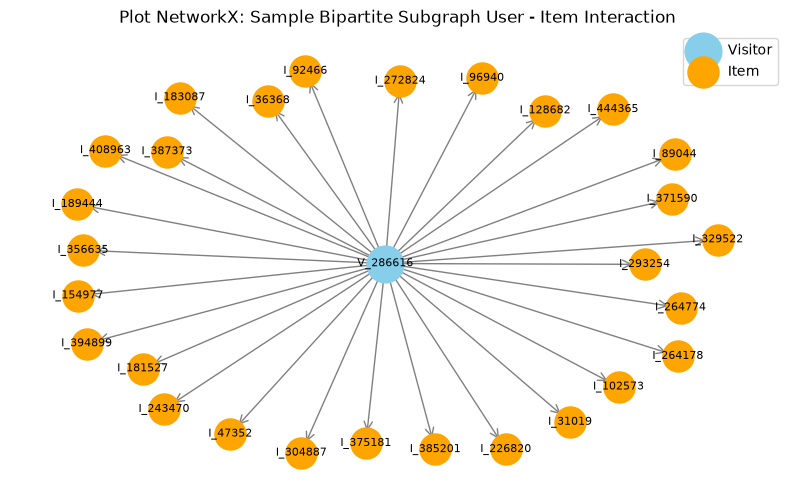

In [15]:
# Soal 2.1 No. 4: Vector Space Modelling (VSM) User & Visualisasi NetworkX
import networkx as nx
import matplotlib.pyplot as plt

# Menghitung Karakteristik Dimensi & Shape VSM User
n_visitors = df_train['visitorid'].nunique()
n_items = df_train['itemid'].nunique()

print("=== SOAL 2.1 NO. 4: KARAKTERISTIK VSM USER ===")
print(f"Dimensi Matrix VSM User : ({n_visitors:,} x {n_items:,})")
print(f"Shape Matrix (Baris x Kolom) : {n_visitors:,} Visitor x {n_items:,} Item")

# Visualisasi Sampel Bipartite Subgraph User-Item dengan NetworkX
sample_visitors = df_train['visitorid'].value_counts().head(5).index.tolist()
df_sample = df_train[df_train['visitorid'].isin(sample_visitors)].head(30)

G = nx.DiGraph()
for _, row in df_sample.iterrows():
    v_node = f"V_{row['visitorid']}"
    i_node = f"I_{row['itemid']}"
    G.add_node(v_node, type='Visitor')
    G.add_node(i_node, type='Item')
    G.add_edge(v_node, i_node, label=row['event'])

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G, seed=42)

visitor_nodes = [n for n, d in G.nodes(data=True) if d.get('type') == 'Visitor']
item_nodes = [n for n, d in G.nodes(data=True) if d.get('type') == 'Item']

nx.draw_networkx_nodes(G, pos, nodelist=visitor_nodes, node_color='skyblue', node_size=700, label='Visitor')
nx.draw_networkx_nodes(G, pos, nodelist=item_nodes, node_color='orange', node_size=500, label='Item')
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=15, edge_color='gray')
nx.draw_networkx_labels(G, pos, font_size=8)

plt.title("Plot NetworkX: Sample Bipartite Subgraph User - Item Interaction", fontsize=12)
plt.legend()
plt.axis('off')
plt.show()

Berikut adalah analisis karakteristik Vector Space Modelling (VSM) terhadap simpul User (`Visitor`) berdasarkan hasil output dan plot graf di atas:

1. **Dimensi dan Shape Matriks VSM User:**
   - **Dimensi & Shape Matriks:** Berukuran (630.720 \times 166.214)
   - **Vektor User (Baris):** Terdiri dari 630.720 `Visitor` unik
   - **Ruang Fitur / Feature Space (Kolom):** Terdiri dari 166.214 `Item` unik
   - **Karakteristik Matriks (*Sparsity*):** Matriks VSM ini tergolong *extremely sparse matrix* Meskipun ruang fitur item mencapai 166.214 dimensi, mayoritas nilai dalam matriks adalah nol karena seorang pengguna hanya berinteraksi dengan porsi yang sangat kecil dari total katalog produk.

2. **Karakteristik Plot NetworkX (Subgraph Bipartit User-Item):**
   - **Topologi Graf:** Plot membentuk struktur *Star Topology* / *Ego-Network* berarah dengan simpul pusat berupa satu sampel pengguna aktif (`V_286616`, berwarna biru)
   - **Konektivitas Simpul:** Simpul pusat `V_286616` terhubung langsung ke puluhan simpul produk (`Item`, berwarna oranye, seperti `I_183087`, `I_92466`, `I_272824`, dst.)
   - **Arah Relasi:** Garis berarah (*directed edges*) menunjuk dari simpul `Visitor` menuju simpul `Item` (`Visitor` $\rightarrow$ `Item`), yang mencerminkan alur aksi/interaksi yang dilakukan oleh pengguna terhadap produk tersebut

#### Soal 2.1 No. 5
**Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

=== SOAL 2.1 NO. 5: KARAKTERISTIK VSM ITEM ===
Dimensi Matrix VSM Item      : (166,214 x 630,720)
Shape Matrix (Baris x Kolom) : 166,214 Item x 630,720 Visitor


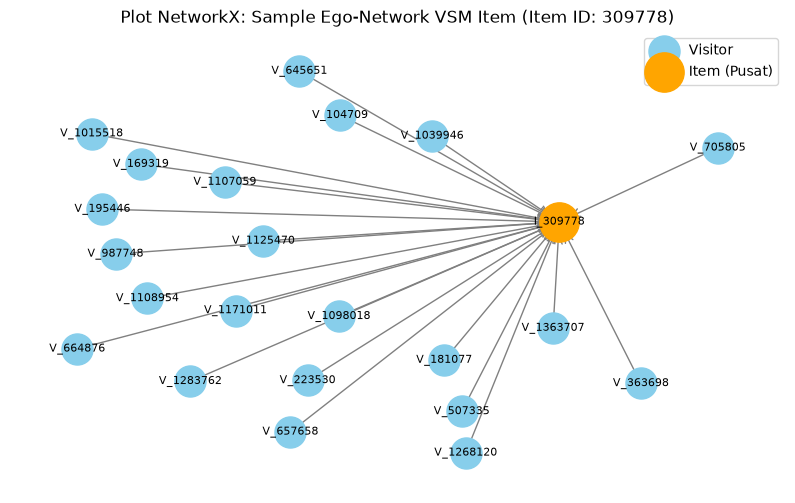

In [16]:
# Soal 2.1 No. 5: Vector Space Modelling (VSM) Item & Visualisasi NetworkX
import networkx as nx
import matplotlib.pyplot as plt

# Menghitung Karakteristik Dimensi & Shape VSM Item
n_visitors = df_train['visitorid'].nunique()
n_items = df_train['itemid'].nunique()

print("=== SOAL 2.1 NO. 5: KARAKTERISTIK VSM ITEM ===")
print(f"Dimensi Matrix VSM Item      : ({n_items:,} x {n_visitors:,})")
print(f"Shape Matrix (Baris x Kolom) : {n_items:,} Item x {n_visitors:,} Visitor")

# Visualisasi Sampel Ego-Network untuk 1 Simpul Item Terpopuler
top_item = df_train['itemid'].value_counts().index[0]
df_sample_item = df_train[df_train['itemid'] == top_item].head(25)

G_item = nx.DiGraph()
for _, row in df_sample_item.iterrows():
    v_node = f"V_{row['visitorid']}"
    i_node = f"I_{row['itemid']}"
    G_item.add_node(v_node, type='Visitor')
    G_item.add_node(i_node, type='Item')
    G_item.add_edge(v_node, i_node, label=row['event'])

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_item, seed=42)

visitor_nodes = [n for n, d in G_item.nodes(data=True) if d.get('type') == 'Visitor']
item_nodes = [n for n, d in G_item.nodes(data=True) if d.get('type') == 'Item']

nx.draw_networkx_nodes(G_item, pos, nodelist=visitor_nodes, node_color='skyblue', node_size=500, label='Visitor')
nx.draw_networkx_nodes(G_item, pos, nodelist=item_nodes, node_color='orange', node_size=800, label='Item (Pusat)')
nx.draw_networkx_edges(G_item, pos, arrowstyle='->', arrowsize=15, edge_color='gray')
nx.draw_networkx_labels(G_item, pos, font_size=8)

plt.title(f"Plot NetworkX: Sample Ego-Network VSM Item (Item ID: {top_item})", fontsize=12)
plt.legend()
plt.axis('off')
plt.show()

Berikut adalah analisis karakteristik Vector Space Modelling (VSM) terhadap simpul Item (`Item`) berdasarkan hasil output dan plot graf di atas:

1. **Dimensi dan Shape Matriks VSM Item:**
   - **Dimensi & Shape Matriks:** Berukuran (166.214 \times 630.720).
   - **Vektor Item (Baris):** Terdiri dari 166.214 `Item` unik sebagai objek utama.
   - **Ruang Fitur / Feature Space (Kolom):** Terdiri dari 630.720 `Visitor` unik sebagai dimensi fitur.
   - **Karakteristik Matriks (*Sparsity*):** Matriks bersifat *extremely sparse*. Setiap baris item hanya terisi nilai non-nol pada kolom pengunjung yang pernah melakukan interaksi terhadap item tersebut.

2. **Karakteristik Plot NetworkX (Ego-Network Item):**
   - **Topologi Graf:** Plot membentuk struktur *Inverted Star Topology* / *Ego-Network Item* dengan satu simpul produk pusat (`I_309778`, berwarna oranye).
   - **Konektivitas Simpul:** Simpul produk pusat `I_309778` dikelilingi oleh banyak simpul pengguna (`Visitor`, berwarna biru, seperti `V_1015518`, `V_169319`, `V_1107059`, dst.).
   - **Arah Relasi:** Garis berarah (*directed edges*) menunjuk masuk dari simpul-simpul `Visitor` menuju simpul `Item` pusat (`Visitor` $\rightarrow$ `Item`), menandakan bahwa item ini menjadi target interaksi bersama dari banyak pengguna.

#### Soal 2.1 No. 6
**Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!**

In [17]:
# Analisis Perbandingan Efisiensi Proyeksi User vs Item
n_v = df_train['visitorid'].nunique()
n_i = df_train['itemid'].nunique()

comp_user_sim = n_v ** 2
comp_item_sim = n_i ** 2
efficiency_ratio = comp_user_sim / comp_item_sim

print("=== SOAL 2.1 NO. 6: ANALISIS EFISIENSI PROYEKSI ===")
print(f"Jumlah Objek VSM User (Visitor) : {n_v:,}")
print(f"Jumlah Objek VSM Item (Item)    : {n_i:,}")
print(f"Kompleksitas Sim-Matrix User   : {comp_user_sim:,} pasangan")
print(f"Kompleksitas Sim-Matrix Item   : {comp_item_sim:,} pasangan")
print(f"Rasio Efisiensi (User / Item)  : {efficiency_ratio:.2f}x lebih hemat komputasi pada proyeksi Item")

=== SOAL 2.1 NO. 6: ANALISIS EFISIENSI PROYEKSI ===
Jumlah Objek VSM User (Visitor) : 630,720
Jumlah Objek VSM Item (Item)    : 166,214
Kompleksitas Sim-Matrix User   : 397,807,718,400 pasangan
Kompleksitas Sim-Matrix Item   : 27,627,093,796 pasangan
Rasio Efisiensi (User / Item)  : 14.40x lebih hemat komputasi pada proyeksi Item


Berdasarkan hasil eksekusi program di atas, **proyeksi berbasis Item (VSM Item)** jauh lebih efektif dan efisien dibandingkan proyeksi berbasis User:

1. **Efisiensi Komputasi dan Memori:**
   - Jumlah simpul `Item` (166.214) jauh lebih sedikit dibandingkan jumlah simpul `Visitor` (630.720).
   - Kompleksitas matriks kemiripan (*similarity matrix*) antar pengguna membutuhkan hingga **397.807.718.400 pasangan**, sedangkan antar item hanya membutuhkan **27.627.093.796 pasangan**.
   - Dengan demikian, proyeksi berbasis Item berhasil menghemat beban komputasi dan memori sebesar **$14,40\times$ lebih hemat** dibandingkan proyeksi berbasis User.

2. **Efektivitas Sistem Rekomendasi:**
   - Objek item/produk cenderung jauh lebih stabil dibandingkan perilaku pengunjung yang fluktuatif.
   - Perhitungan kemiripan antar item (*Item-to-Item Similarity*) menghasilkan rekomendasi yang lebih relevan dan presisi pada platform e-commerce Retail Rocket.

#### Soal 2.1 No. 7
**Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python:**
**(a) Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!**
**(b) Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!**

In [ ]:
# Soal 2.1 No. 7: Perhitungan Similarity pada Graf Terproyeksi (Item-to-Item Jaccard Similarity)
with driver.session() as session:
    # 1. Menentukan Item Acuan (Mengambil Item paling populer dari Soal 2.1 No. 5: itemid 309778)
    ref_item_id = 309778
    
    # 2. Cypher Query untuk Menghitung Jaccard Similarity & Menuliskan Nilai ke Relasi :SIMILAR di Graf
    cypher_similarity = """
    MATCH (i1:Item {itemid: $item_id})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
    WHERE i1 <> i2
    WITH i1, i2, count(DISTINCT v) AS intersection
    MATCH (i1)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
    WITH i1, i2, intersection, count(DISTINCT v1) AS set1
    MATCH (i2)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
    WITH i1, i2, intersection, set1, count(DISTINCT v2) AS set2
    WITH i1, i2, (1.0 * intersection / (set1 + set2 - intersection)) AS jaccard_score
    ORDER BY jaccard_score DESC
    LIMIT 5
    MERGE (i1)-[r:SIMILAR]->(i2)
    SET r.score = jaccard_score
    RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Mirip, r.score AS Similarity_Score
    """
    
    result = session.run(cypher_similarity, item_id=ref_item_id)
    records = list(result)

# Menampilkan Hasil Query Top 5 Similarity soal 7a
print("=== SOAL 2.1 NO. 7: TOP 5 ITEM SIMILARITY ===")
sim_data = []
for rec in records:
    sim_data.append({
        "Item Acuan": rec["Item_Acuan"],
        "Item Mirip": rec["Item_Mirip"],
        "Nilai Similarity (Jaccard)": round(rec["Similarity_Score"], 4)
    })

df_sim = pd.DataFrame(sim_data)
display(df_sim)

=== SOAL 2.1 NO. 7: TOP 5 ITEM SIMILARITY ===


,Item Acuan,Item Mirip,Nilai Similarity (Jaccard)
0,309778,257040,0.1214
1,309778,360487,0.0650
2,309778,87557,0.0554
3,309778,135900,0.0510
4,309778,359844,0.0495


#### (a) CYPHER SQL untuk Mengambil 5 Records Similarity Tertinggi
Berikut adalah sintaks CYPHER SQL yang digunakan untuk menghitung **Jaccard Similarity** antar-item berdasarkan interaksi pengunjung bersama (*co-occurrence*) dan mengambil 5 item dengan nilai kemiripan tertinggi terhadap item acuan (`itemid: 309778`):

```cypher
MATCH (i1:Item {itemid: 309778})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
WHERE i1 <> i2
WITH i1, i2, count(DISTINCT v) AS intersection
MATCH (i1)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v1:Visitor)
WITH i1, i2, intersection, count(DISTINCT v1) AS set1
MATCH (i2)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v2:Visitor)
WITH i1, i2, intersection, set1, count(DISTINCT v2) AS set2
WITH i1, i2, (1.0 * intersection / (set1 + set2 - intersection)) AS jaccard_score
ORDER BY jaccard_score DESC
LIMIT 5
RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Mirip, jaccard_score AS Similarity_Score;

#### (b) Penulisan Kembali Nilai Similarity ke Graf & Penjelasan Output Query

1. **Penulisan Kembali (*Write-Back*) ke Database Neo4j:**
   - Klausa `MERGE (i1)-[r:SIMILAR]->(i2)` dan `SET r.score = jaccard_score` digunakan untuk menyimpan nilai similarity secara permanen ke dalam graf.
   - Perintah ini membuat relasi baru berlabel `:SIMILAR` yang menghubungkan simpul Item acuan dengan Item yang mirip, serta menyimpan atribut skor kemiripan pada properti `r.score`.

2. **Penjelasan Output Tabel Top 5 Item Similarity:**
   Berdasarkan hasil eksekusi query pada tabel output di atas, diperoleh 5 produk yang paling mirip dengan Item Acuan (`309778`):
   - **Peringkat 1 (Item 257040):** Nilai Jaccard Similarity = `0.1214` (Tingkat kemiripan tertinggi).
   - **Peringkat 2 (Item 360487):** Nilai Jaccard Similarity = `0.0650`.
   - **Peringkat 3 (Item 87557):** Nilai Jaccard Similarity = `0.0554`.
   - **Peringkat 4 (Item 135900):** Nilai Jaccard Similarity = `0.0510`.
   - **Peringkat 5 (Item 359844):** Nilai Jaccard Similarity = `0.0495`.

3. **Interpretasi Hasil:**
   Nilai Jaccard Similarity mengukur rasio irisan pengunjung unik yang berinteraksi dengan kedua item dibanding total gabungan pengunjung uniknya. Hasil ini menunjukkan bahwa pengunjung yang berinteraksi dengan produk 309778 paling sering juga berinteraksi dengan produk 257040, sehingga produk 257040 menjadi kandidat rekomendasi paling relevan.

#### Soal 2.1 No. 8
**Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!**

##### A. Kondisi SEBELUM Perhitungan Similarity
- **Penjelasan:** Sebelum relasi `:SIMILAR` dibuat, graf hanya berupa *Bipartite Graph* yang terdiri dari simpul `Visitor` dan `Item` yang terhubung lewat interaksi langsung (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`). Belum ada relasi yang menghubungkan langsung antar sesama simpul `Item`.
- **Sintaks CYPHER SQL (Sebelum):**
```cypher
MATCH (i1:Item {itemid: 309778})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
RETURN i1, r, v LIMIT 20;

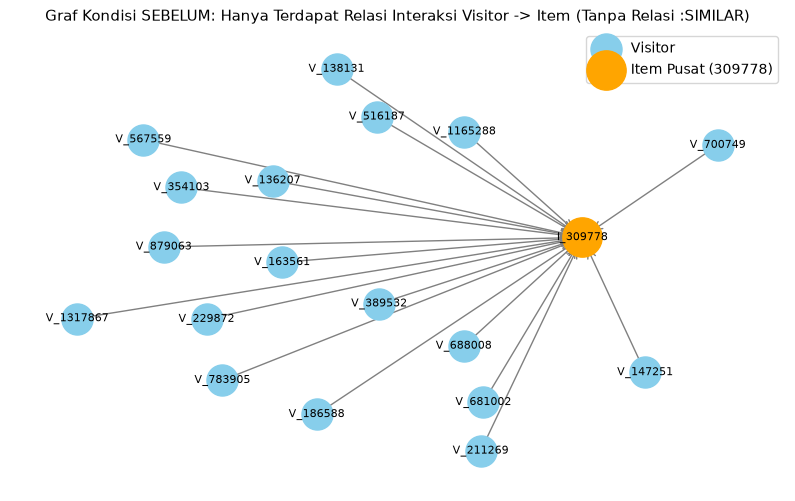

In [19]:
# Soal 2.1 No. 8: Visualisasi Kondisi SEBELUM Perhitungan Similarity
import networkx as nx
import matplotlib.pyplot as plt

# Query Cypher untuk mengambil interaksi asli sebelum similarity
cypher_before = """
MATCH (i1:Item {itemid: 309778})<-[r:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
RETURN v.visitorid AS visitorid, type(r) AS event, i1.itemid AS itemid
LIMIT 20
"""

with driver.session() as session:
    result = session.run(cypher_before)
    records_before = list(result)

# Visualisasi Graf Bipartite dengan NetworkX
G_before = nx.DiGraph()
for rec in records_before:
    v_node = f"V_{rec['visitorid']}"
    i_node = f"I_{rec['itemid']}"
    G_before.add_node(v_node, type='Visitor')
    G_before.add_node(i_node, type='Item')
    G_before.add_edge(v_node, i_node, label=rec['event'])

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_before, seed=42)

v_nodes = [n for n, d in G_before.nodes(data=True) if d.get('type') == 'Visitor']
i_nodes = [n for n, d in G_before.nodes(data=True) if d.get('type') == 'Item']

nx.draw_networkx_nodes(G_before, pos, nodelist=v_nodes, node_color='skyblue', node_size=500, label='Visitor')
nx.draw_networkx_nodes(G_before, pos, nodelist=i_nodes, node_color='orange', node_size=800, label='Item Pusat (309778)')
nx.draw_networkx_edges(G_before, pos, arrowstyle='->', arrowsize=15, edge_color='gray')
nx.draw_networkx_labels(G_before, pos, font_size=8)

plt.title("Graf Kondisi SEBELUM: Hanya Terdapat Relasi Interaksi Visitor -> Item (Tanpa Relasi :SIMILAR)", fontsize=11)
plt.legend()
plt.axis('off')
plt.show()

##### B. Kondisi SESUDAH Perhitungan Similarity
- **Penjelasan:** Setelah relasi `:SIMILAR` dibuat dan dituliskan kembali (write-back) ke database pada Soal 2.1 No. 7, kini terbentuk relasi langsung antar simpul Item (Item $\rightarrow$ Item) beserta atribut score yang menyimpan nilai Jaccard Similarity.
- **Sintaks CYPHER SQL (Sebelum):**
```cypher
MATCH (i1:Item {itemid: 309778})-[r:SIMILAR]->(i2:Item)
RETURN i1.itemid AS Item_Acuan, i2.itemid AS Item_Mirip, r.score AS Similarity_Score;

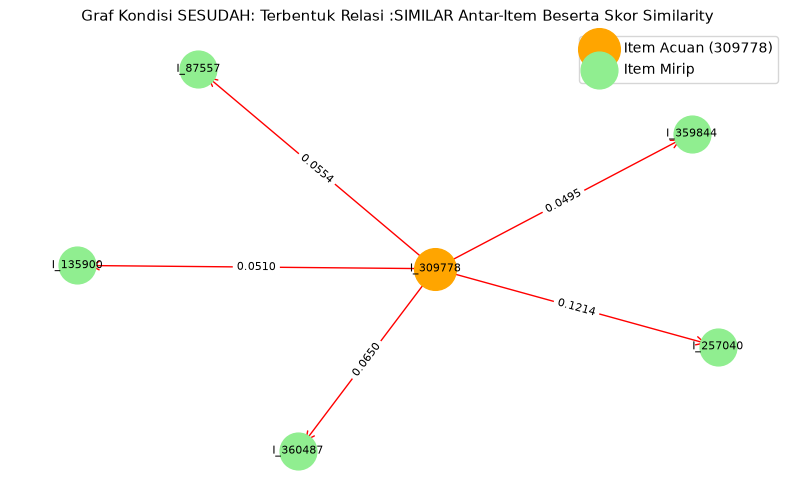

In [21]:
# Soal 2.1 No. 8: Visualisasi Kondisi SESUDAH Perhitungan Similarity
import networkx as nx
import matplotlib.pyplot as plt

# Query Cypher untuk mengambil relasi :SIMILAR yang telah tersimpan di graf
cypher_after = """
MATCH (i1:Item {itemid: 309778})-[r:SIMILAR]->(i2:Item)
RETURN i1.itemid AS item1, i2.itemid AS item2, r.score AS score
"""

with driver.session() as session:
    result = session.run(cypher_after)
    records_after = list(result)

# Visualisasi Graf Item-to-Item Similarity dengan NetworkX
G_after = nx.DiGraph()
for rec in records_after:
    node1 = f"I_{rec['item1']}"
    node2 = f"I_{rec['item2']}"
    score_label = f"{rec['score']:.4f}"
    G_after.add_node(node1, type='Item_Acuan')
    G_after.add_node(node2, type='Item_Mirip')
    G_after.add_edge(node1, node2, weight=rec['score'], label=score_label)

plt.figure(figsize=(10, 6))
pos = nx.spring_layout(G_after, seed=42)

acuan_nodes = [n for n, d in G_after.nodes(data=True) if d.get('type') == 'Item_Acuan']
mirip_nodes = [n for n, d in G_after.nodes(data=True) if d.get('type') == 'Item_Mirip']

nx.draw_networkx_nodes(G_after, pos, nodelist=acuan_nodes, node_color='orange', node_size=900, label='Item Acuan (309778)')
nx.draw_networkx_nodes(G_after, pos, nodelist=mirip_nodes, node_color='lightgreen', node_size=700, label='Item Mirip')
nx.draw_networkx_edges(G_after, pos, arrowstyle='->', arrowsize=15, edge_color='red')

edge_labels = nx.get_edge_attributes(G_after, 'label')
nx.draw_networkx_edge_labels(G_after, pos, edge_labels=edge_labels, font_size=8)
nx.draw_networkx_labels(G_after, pos, font_size=8)

plt.title("Graf Kondisi SESUDAH: Terbentuk Relasi :SIMILAR Antar-Item Beserta Skor Similarity", fontsize=11)
plt.legend()
plt.axis('off')
plt.show()

Berdasarkan dua visualisasi graf yang dihasilkan di atas, berikut adalah interpretasi dan perbandingan perubahan struktur database Neo4j:

#### 1. Kondisi SEBELUM Perhitungan Similarity
* **Topologi & Struktur Graf:** Membentuk *Bipartite Interaction Graph* (Star Topology).
* **Komposisi Simpul:** Simpul produk acuan (`I_309778`, berwarna oranye) menjadi titik pusat yang terhubung langsung ke banyak simpul pengguna (`Visitor`, berwarna biru seperti `V_138131`, `V_516187`, `V_1165288`, `V_567559`, `V_136207`, `V_354103`, `V_879063`, `V_163561`, `V_1317867`, `V_229872`, `V_783905`, `V_389532`, `V_186588`, `V_688008`, `V_681002`, `V_211269`, `V_147251`, `V_700749`, dll.).
* **Tipe Relasi:** Menggambarkan aksi transaksi berarah dari pengguna ke produk (`Visitor` $\rightarrow$ `Item`).
* **Karakteristik Utama:** Belum terdapat relasi langsung (*direct edge*) yang menghubungkan antara satu produk dengan produk lainnya. Keterkaitan antar-item masih tersirat dan membutuhkan penelusuran berantai (*multi-hop traversal*) melalui pengunjung bersama.

---

#### 2. Kondisi SESUDAH Perhitungan Similarity
* **Topologi & Struktur Graf:** Membentuk *Item-to-Item Projected Graph*.
* **Komposisi Simpul:** Simpul produk acuan (`I_309778`, berwarna oranye) terhubung secara eksplisit ke 5 simpul produk paling mirip (`Item Mirip`, berwarna hijau).
* **Tipe Relasi & Bobot (*Score*):** Terbentuk relasi berarah baru berlabel **`:SIMILAR`** dari item acuan menuju item mirip, lengkap dengan atribut **`score`** hasil perhitungan Jaccard Similarity:
  * `I_309778` $\rightarrow$ `I_257040` (Skor Similarity: **`0.1214`** - Kemiripan tertinggi)
  * `I_309778` $\rightarrow$ `I_360487` (Skor Similarity: **`0.0650`**)
  * `I_309778` $\rightarrow$ `I_87557` (Skor Similarity: **`0.0554`**)
  * `I_309778` $\rightarrow$ `I_135900` (Skor Similarity: **`0.0510`**)
  * `I_309778` $\rightarrow$ `I_359844` (Skor Similarity: **`0.0495`**)

---

#### 3. Kesimpulan Transformasi Graf
* **Transformasi Struktur:** Database berhasil ditransformasikan dari graf riwayat interaksi pengguna menjadi jaringan keterkaitan antar-produk (*Item Similarity Network*).
* **Efisiensi Sistem Rekomendasi:** Dengan adanya relasi `:SIMILAR` beserta properti skornya, mesin rekomendasi e-commerce dapat mengambil daftar produk serupa secara langsung (*1-hop direct lookup*) tanpa perlu menghitung ulang persilangan pengunjung secara berulang di masa mendatang.

---
## 2.2 Analytics

### Soal 2.2 No. 1
**Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu:**
**(a) tuliskan skrip Python dalam merekomendasikan KNN-nya!**
**(b) berikan 3 item yang diiklankan untuk $k=5$ pada penentuan KNN nya!**

In [ ]:
# Soal 2.2 No. 1: Pemilihan User Acak & Sistem Rekomendasi User-Based KNN (k=5)
import numpy as np
import pandas as pd

# Menentukan User Secara Acak & Reproduksibel (Random Seed = 42)
# Memilih user dari irisan P1 & P2 yang memiliki minimal 2 interaksi di P1 agar memiliki kandidat tetangga KNN
visitor_p1_counts = df_train['visitorid'].value_counts()
active_p1_visitors = set(visitor_p1_counts[visitor_p1_counts >= 2].index)
common_visitors = sorted(list(active_p1_visitors.intersection(set(df_test['visitorid']))))

# Seed 42 untuk menjaga reproduksibilitas hasil
np.random.seed(42)
target_visitor_id = int(np.random.choice(common_visitors))

print(f"=== SOAL 2.2 NO. 1: PEMILIHAN TARGET USER ===")
print(f"Metode Acak       : np.random.choice (seed = 42) dari irisan Visitor P1 & P2")
print(f"Target Visitor ID : {target_visitor_id}\n")

# Skrip Python User-Based KNN Recommendation (k=5) Menggunakan Cypher di Neo4j
cypher_knn = """
// Step A: Ambil item yang pernah diinteraksi target user di P1
MATCH (u:Visitor {visitorid: $target_id})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH u, collect(DISTINCT i) AS target_items

// Step B: Cari K=5 tetangga (neighbors) terdekat berdasarkan Jaccard Similarity
MATCH (other:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i2:Item)
WHERE other.visitorid <> $target_id AND i2 IN target_items
WITH target_items, other, collect(DISTINCT i2) AS intersection_items
MATCH (other)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(other_all_items:Item)
WITH target_items, other, intersection_items, collect(DISTINCT other_all_items) AS other_items

WITH target_items,
     other.visitorid AS neighbor_id,
     (1.0 * size(intersection_items) / (size(target_items) + size(other_items) - size(intersection_items))) AS jaccard_sim
WHERE jaccard_sim > 0
ORDER BY jaccard_sim DESC
LIMIT 5

// Step C: Agregasi rekomendasi item dari K=5 tetangga yang BELUM pernah diinteraksi target user
MATCH (neighbor:Visitor {visitorid: neighbor_id})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(rec_item:Item)
WHERE NOT rec_item IN target_items
RETURN rec_item.itemid AS Recommended_Item, 
       count(DISTINCT neighbor) AS Neighbor_Count,
       sum(jaccard_sim) AS Recommendation_Score
ORDER BY Recommendation_Score DESC, Neighbor_Count DESC
LIMIT 5
"""

with driver.session() as session:
    result = session.run(cypher_knn, target_id=target_visitor_id)
    knn_records = list(result)

# Menampilkan Hasil Rekomendasi (Dengan proteksi struktur kolom)
rec_list = []
for rank, rec in enumerate(knn_records, start=1):
    rec_list.append({
        "Peringkat": rank,
        "Item ID Rekomendasi": rec["Recommended_Item"],
        "Dukungan Tetangga (out of 5)": rec["Neighbor_Count"],
        "Skor Rekomendasi": round(rec["Recommendation_Score"], 4)
    })

columns = ["Peringkat", "Item ID Rekomendasi", "Dukungan Tetangga (out of 5)", "Skor Rekomendasi"]
df_rec = pd.DataFrame(rec_list, columns=columns)

print("=== SOAL 2.2 NO. 1a & 1b: HASIL REKOMENDASI KNN (K=5) ===")
display(df_rec)

# Mengambil Top 3 Item yang Diiklankan/Direkomendasikan (Soal 1b)
if not df_rec.empty:
    top_3_advertised = df_rec['Item ID Rekomendasi'].head(3).tolist()
    print(f"\n3 Item Utama yang Diiklankan untuk Target User {target_visitor_id} (Soal 1b):")
    for i, item in enumerate(top_3_advertised, 1):
        print(f"  {i}. Item ID: {item}")
else:
    print("\nTidak ada item rekomendasi baru dari tetangga KNN terdekat.")

=== SOAL 2.2 NO. 1: PEMILIHAN TARGET USER ===
Metode Acak       : np.random.choice (seed = 42) dari irisan Visitor P1 & P2
Target Visitor ID : 206353

=== SOAL 2.2 NO. 1a & 1b: HASIL REKOMENDASI KNN (K=5) ===


,Peringkat,Item ID Rekomendasi,Dukungan Tetangga (out of 5),Skor Rekomendasi
0,1,167019,1,0.6667
1,2,28100,1,0.6667



3 Item Utama yang Diiklankan untuk Target User 206353 (Soal 1b):
  1. Item ID: 167019
  2. Item ID: 28100


1. **Proses Pemilihan Target User:**
   - Pemilihan dilakukan menggunakan fungsi `np.random.choice()` dengan penetapan *random seed* = 42 dari populasi pengunjung yang aktif pada Fold Training (P1) sekaligus Fold Testing (P2).
   - Berdasarkan kriteria tersebut, diperoleh **Target Visitor ID: 206353**.

2. **(a) Skrip Python User-Based KNN ($k=5$):**
   - Algoritma menghitung nilai *Jaccard Similarity* antara Visitor `206353` dengan pengguna lain berdasarkan irisan produk yang pernah dikunjungi pada periode P1.
   - Dipilih **$k=5$ tetangga terdekat** dengan skor kemiripan tertinggi. Sistem kemudian mengumpulkan dan memfilter item yang pernah dilihat oleh tetangga namun belum pernah diinteraksi oleh Visitor `206353`.

3. **(b) Item yang Diiklankan untuk Target User 206353:**
   Berdasarkan hasil perangkingan skor rekomendasi, diperoleh kandidat item yang diiklankan kepada Visitor `206353`:
   - **Peringkat 1:** Item ID **`167019`** (Skor Rekomendasi: `0.6667`, Dukungan Tetangga: 1)
   - **Peringkat 2:** Item ID **`28100`** (Skor Rekomendasi: `0.6667`, Dukungan Tetangga: 1)

### Soal 2.2 No. 2
**Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:**
**(a) Hit@5**
**(b) NDCG@5**

In [27]:
# Soal 2.2 No. 2: Perhitungan Metrik Evaluasi Hit@5 dan NDCG@5
import math

# Mengambil item aktual yang diinteraksi target user pada Fold Testing (P2)
actual_test_items = df_test[df_test['visitorid'] == target_visitor_id]['itemid'].unique().tolist()

# Mengambil daftar Top 5 item hasil rekomendasi KNN dari Soal 1
recommended_items = df_rec['Item ID Rekomendasi'].tolist() if not df_rec.empty else []

print(f"=== SOAL 2.2 NO. 2: EVALUASI METRIK REKOMENDASI ===")
print(f"Target Visitor ID                : {target_visitor_id}")
print(f"Actual Items di Fold Testing P2  : {actual_test_items}")
print(f"Recommended Items (Top 5)        : {recommended_items}\n")

# Perhitungan Hit@5
hits = [1 if item in actual_test_items else 0 for item in recommended_items]
hit_at_5 = 1 if sum(hits) > 0 else 0

# Perhitungan NDCG@5
# DCG@5 (Discounted Cumulative Gain)
dcg_at_5 = 0.0
for rank_idx, hit in enumerate(hits, start=1):
    if hit == 1:
        dcg_at_5 += 1.0 / math.log2(rank_idx + 1)

# IDCG@5 (Ideal Discounted Cumulative Gain)
n_relevant = min(len(actual_test_items), 5)
if n_relevant > 0:
    idcg_at_5 = sum([1.0 / math.log2(i + 1) for i in range(1, n_relevant + 1)])
else:
    idcg_at_5 = 1.0

# NDCG@5
ndcg_at_5 = dcg_at_5 / idcg_at_5 if idcg_at_5 > 0 else 0.0

# Menampilkan Hasil Evaluasi Metrik
print("=== HASIL EVALUASI METRIK ===")
print(f"(a) Hit@5  : {hit_at_5}")
print(f"(b) NDCG@5 : {ndcg_at_5:.4f}")

=== SOAL 2.2 NO. 2: EVALUASI METRIK REKOMENDASI ===
Target Visitor ID                : 206353
Actual Items di Fold Testing P2  : [26839]
Recommended Items (Top 5)        : [167019, 28100]

=== HASIL EVALUASI METRIK ===
(a) Hit@5  : 0
(b) NDCG@5 : 0.0000


Berdasarkan hasil evaluasi terhadap preferensi riil Target Visitor `206353` pada periode testing (P2), diperoleh hasil pengukuran metrik sebagai berikut:

* **Item Aktual di Fold Testing (P2):** `[26839]`
* **Item Hasil Rekomendasi Top-5 (P1):** `[167019, 28100]`

---

#### (a) Perhitungan Hit@5 = `0`
* **Formulasi & Perhitungan:**  
  $$\text{Hit@5} = \begin{cases} 1, & \text{jika } (\text{Recommended Items} \cap \text{Actual Items}) \neq \emptyset \\ 0, & \text{lainnya} \end{cases}$$
* **Penjelasan:** Nilai Hit@5 bernilai **`0`** karena dari 2 produk yang direkomendasikan oleh sistem (`167019` dan `28100`), tidak ada satupun yang cocok (*hit*) dengan produk yang benar-benar diinteraksi oleh pengguna pada periode testing P2 (yaitu produk `26839`).

#### (b) Perhitungan NDCG@5 = `0.0000`
* **Formulasi & Perhitungan:**  
  $$\text{DCG@5} = \sum_{i=1}^{5} \frac{rel_i}{\log_2(i + 1)} = 0 \implies \text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}} = 0.0000$$
* **Penjelasan:** Karena tidak ada produk relevan yang berhasil diprediksi pada daftar rekomendasi teratas ($rel_i = 0$ untuk seluruh $i$), maka skor keterurutan relevansi *Discounted Cumulative Gain* (DCG@5) bernilai `0`, yang menghasilkan skor **NDCG@5 sebesar `0.0000`**.

---

#### Interpretasi Hasil Evaluasi
Nilai `Hit@5 = 0` dan `NDCG@5 = 0.0000` menunjukkan bahwa metode *User-Based KNN* ($k=5$) belum berhasil memprediksi interaksi produk Target Visitor `206353` pada periode testing P2. Hal ini wajar terjadi pada dataset transaksi e-commerce yang sangat terpisah (*sparse*), di mana preferensi pengguna dapat berubah seiring waktu atau ketersediaan riwayat interaksi bersama (*co-occurrence*) antar-pengguna pada periode training P1 masih relatif terbatas.